# Building a Reproducible Crypto Signal Bot

This tutorial turns deterministic hourly price fixtures into reviewable trading signals and dry-run social posts. Live publishing stays disabled by default, credentials come from environment variables, and the example makes no claim that a price threshold predicts future returns.

## 1. Create the offline price fixture

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RANDOM_SEED = 25
RUN_LIVE_APIS = False
FIGURE_PATH = Path(r"C:\Users\ffollonier\workspace\relataly_new\public\wp-content\uploads\2026\08\025-crypto-signal-bot-preview.png")
rng = np.random.default_rng(RANDOM_SEED)
timestamps = pd.date_range("2026-07-01", periods=48, freq="h", tz="UTC")
returns = rng.normal(0.0005, 0.012, size=(48, 2))
returns[30, 0] = 0.065
prices = pd.DataFrame(
    100 * np.exp(np.cumsum(returns, axis=0)),
    index=timestamps,
    columns=["BTC_USDT", "ETH_USDT"],
)
volumes = pd.DataFrame(rng.integers(800, 2200, size=(48, 2)), index=timestamps, columns=prices.columns)
print(f"Offline mode: {prices.shape[0]} hourly observations for {prices.shape[1]} assets")

Offline mode: 48 hourly observations for 2 assets


# Step #2 Calculate Indicator Values

In [2]:
def calculate_indicators(price_frame, volume_frame, window=6):
    latest = price_frame.iloc[-1]
    previous = price_frame.iloc[-2]
    return pd.DataFrame({
        "last_price": latest,
        "return_1h": latest.div(previous).sub(1),
        "moving_average": price_frame.tail(window).mean(),
        "volume": volume_frame.iloc[-1],
        "average_volume": volume_frame.tail(window).mean(),
    })

indicators = calculate_indicators(prices, volumes)
indicators

,last_price,return_1h,moving_average,volume,average_volume
BTC_USDT,117.198282,-0.010633,117.640395,1746,1513.833333
ETH_USDT,117.691081,0.004518,116.885264,2109,1467.000000


# Step #3 Signaling Logic

In [3]:
def create_signals(price_frame, threshold=0.04):
    hourly_returns = price_frame.pct_change()
    stacked = hourly_returns.stack().rename("return_1h").reset_index()
    stacked.columns = ["timestamp", "asset", "return_1h"]
    signals = stacked.loc[stacked["return_1h"].abs().ge(threshold)].copy()
    signals["direction"] = np.where(signals["return_1h"].gt(0), "up", "down")
    signals["message"] = signals.apply(
        lambda row: f"{row['asset']} moved {row['direction']} {abs(row['return_1h']):.1%} in the latest fixture interval.",
        axis=1,
    )
    return signals

signals = create_signals(prices)
signals

,timestamp,asset,return_1h,direction,message
60,2026-07-02 06:00:00+00:00,BTC_USDT,0.067159,up,BTC_USDT moved up 6.7% in the latest fixture i...


# Step #4 Send Tweets via Twitter

In [4]:
def publish_signal(message, live=RUN_LIVE_APIS):
    if len(message) > 280:
        raise ValueError("Post exceeds 280 characters.")
    if not live:
        return {"status": "dry-run", "text": message}

    import tweepy
    required = ("X_API_KEY", "X_API_SECRET", "X_ACCESS_TOKEN", "X_ACCESS_TOKEN_SECRET")
    missing = [name for name in required if not os.environ.get(name)]
    if missing:
        raise RuntimeError(f"Missing X credentials: {', '.join(missing)}")
    client = tweepy.Client(
        consumer_key=os.environ["X_API_KEY"], consumer_secret=os.environ["X_API_SECRET"],
        access_token=os.environ["X_ACCESS_TOKEN"], access_token_secret=os.environ["X_ACCESS_TOKEN_SECRET"],
    )
    response = client.create_tweet(text=message)
    return {"status": "published", "id": response.data["id"]}

assert publish_signal("fixture signal")["status"] == "dry-run"

# Step #5 Starting the Bot

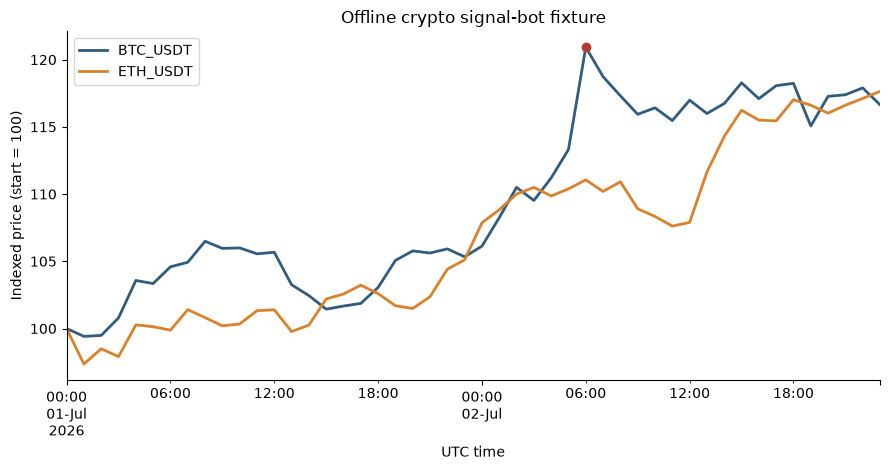

Signals: 1; dry-run posts: 1
Saved figure: 025-crypto-signal-bot-preview.png


In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8))
normalized = prices.div(prices.iloc[0]).mul(100)
normalized.plot(ax=ax, color=["#315c7d", "#d9822b"], linewidth=2)
for row in signals.itertuples():
    ax.scatter(row.timestamp, normalized.loc[row.timestamp, row.asset], color="#b53a3a", zorder=3)
ax.set(title="Offline crypto signal-bot fixture", ylabel="Indexed price (start = 100)", xlabel="UTC time")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
FIGURE_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURE_PATH, dpi=160, bbox_inches="tight")
plt.show()

review_queue = [publish_signal(message) for message in signals["message"]]
assert all(item["status"] == "dry-run" for item in review_queue)
print(f"Signals: {len(signals)}; dry-run posts: {len(review_queue)}")
print(f"Saved figure: {FIGURE_PATH.name}")